In [1]:
import matplotlib.pyplot as plt

In [3]:
CATEGORICAL_COLUMNS = ("Attrition", "BusinessTravel", "Department", "Gender", "JobRole", "OverTime")
ORDINAL_COLUMNS = ("EnvironmentSatisfaction", "JobInvolvement", "JobSatisfaction", "WorkLifeBalance")

def read_file(filename):
    """
    Opens a file and returns an array (two-dimensional if 2+ columns).
    Splits lines by comma and trims any leading or trailing whitespaces.
    """

    with open(filename) as file:
        lines = file.read().splitlines()

        # check if further processing for 2d arrays is required
        if "," in lines[0]:
            for k, v in enumerate(lines):
                split_line = v.split(",")

                for i, entry in enumerate(split_line):
                    entry = entry.strip()
                    try:
                        entry = float(entry)
                    except ValueError:
                        pass
                    split_line[i] = entry

                lines[k] = split_line

        return lines


def fix_data(data, headers):
    print(f"Initial number of rows: {len(data)}")

    averages = {}
    change = {}  # mark specific entries to change to avoid unnecessary comparisons

    remove = set()

    for index, header in enumerate(headers):

        categorical = header in CATEGORICAL_COLUMNS

        missing_values = 0

        running_total = 0
        included_entries = 0

        for row_index, row in enumerate(data):
            if row[index] == "":
                missing_values += 1

                if categorical:
                    remove.add(row_index)
                else:
                    if header not in change:
                        change[header] = []

                    change[header].append(row)

            elif not categorical:
                running_total += row[index]
                included_entries += 1

        if missing_values > 0:
            print(f"{header}: {missing_values} values missing ({'rows removed' if categorical else 'imputed'})")

            if not categorical:
                average = running_total / included_entries

                if header in ORDINAL_COLUMNS:
                    average = int(round(average))  # ordinal values cannot be decimal

                averages[header] = average

    removed = 0
    for index in range(len(data)):
        if index in remove:
            del data[index - removed]
            removed += 1
    print(f"Rows removed due to categorical missing values: {removed}")

    headers_to_change = list(change.keys())

    for header in headers_to_change:
        average = averages[header]
        index = headers.index(header)

        for row in change[header]:
            row[index] = average

    print(f"Remaining number of rows: {len(data)}")

    # verify everything has been imputed/removed
    for row in data:
        assert "" not in row, "Value missing from fixed data!"

    print("\nConfirmed: No missing values remain in the dataset.")


data = read_file("train.csv")
headers = data.pop(0)

fix_data(data, headers)


Initial number of rows: 1029
Age: 64 values missing (imputed)
Attrition: 53 values missing (rows removed)
BusinessTravel: 44 values missing (rows removed)
Department: 51 values missing (rows removed)
DistanceFromHome: 53 values missing (imputed)
EnvironmentSatisfaction: 52 values missing (imputed)
Gender: 49 values missing (rows removed)
JobInvolvement: 67 values missing (imputed)
JobRole: 50 values missing (rows removed)
JobSatisfaction: 47 values missing (imputed)
NumCompaniesWorked: 55 values missing (imputed)
MonthlyIncome: 65 values missing (imputed)
OverTime: 36 values missing (rows removed)
PercentSalaryHike: 54 values missing (imputed)
WorkLifeBalance: 59 values missing (imputed)
YearsAtCompany: 34 values missing (imputed)
YearsInCurrentRole: 39 values missing (imputed)
YearsSinceLastPromotion: 52 values missing (imputed)
Rows removed due to categorical missing values: 259
Remaining number of rows: 770

Confirmed: No missing values remain in the dataset.


18
18


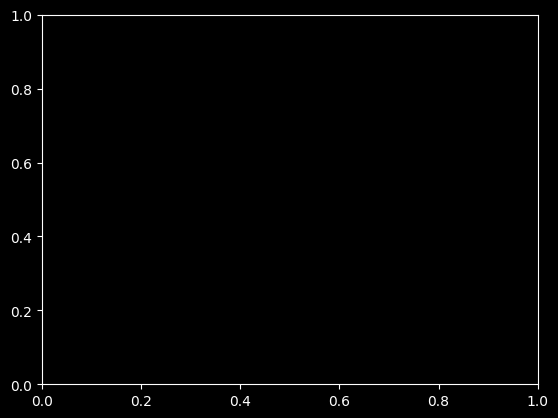

In [6]:
fig, ax = plt.subplots()

print(data[0])
print(headers)